In [157]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from imblearn.over_sampling import SMOTE

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.feature_selection import f_classif, SelectFpr

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay)

In [158]:
ecom_data = pd.read_csv('./ecommerce_return_classification.csv')

In [159]:
ecom_data.head()

,cart_value_usd,past_return_rate,size_bracketing_flag,delivery_days_taken,discount_pct_applied,product_category,fit_review_sentiment,newsletter_subscriber,browser_used,checkout_device,packaging_color,loyalty_card_color,return_risk_label
0,172.17,0.233,1,11,10,Footwear,True-to-Size,1,Safari,Android-App,Kraft-Brown,Platinum,1
1,213.55,0.235,1,6,40,Accessories,True-to-Size,0,Firefox,Android-App,Branded-Teal,Silver,0
2,371.70,0.461,1,11,40,Formal-Eveningwear,True-to-Size,0,Firefox,iOS-App,Kraft-Brown,Gold,1
3,317.18,0.080,0,1,20,Footwear,Inconsistent-Sizing,0,Firefox,iOS-App,Kraft-Brown,Gold,1
4,152.68,0.133,0,3,40,Accessories,True-to-Size,0,Edge,iOS-App,Branded-Teal,Silver,0


In [160]:
ecom_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2993 entries, 0 to 2992
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   cart_value_usd         2993 non-null   float64
 1   past_return_rate       2993 non-null   float64
 2   size_bracketing_flag   2993 non-null   int64  
 3   delivery_days_taken    2993 non-null   int64  
 4   discount_pct_applied   2993 non-null   int64  
 5   product_category       2993 non-null   str    
 6   fit_review_sentiment   2993 non-null   str    
 7   newsletter_subscriber  2993 non-null   int64  
 8   browser_used           2993 non-null   str    
 9   checkout_device        2993 non-null   str    
 10  packaging_color        2993 non-null   str    
 11  loyalty_card_color     2993 non-null   str    
 12  return_risk_label      2993 non-null   int64  
dtypes: float64(2), int64(5), str(6)
memory usage: 481.6 KB


In [161]:
numerical_features = [
    "cart_value_usd",
    "past_return_rate",
    "delivery_days_taken",
    "discount_pct_applied",
]

categorical_features = [
    "product_category",
    "fit_review_sentiment",
    "browser_used",
    "checkout_device",
    "packaging_color",
    "loyalty_card_color",
    "size_bracketing_flag",
    "newsletter_subscriber",
]

print('Numerical Features:', numerical_features)
print('Categorical Features:', categorical_features)

Numerical Features: ['cart_value_usd', 'past_return_rate', 'delivery_days_taken', 'discount_pct_applied']
Categorical Features: ['product_category', 'fit_review_sentiment', 'browser_used', 'checkout_device', 'packaging_color', 'loyalty_card_color', 'size_bracketing_flag', 'newsletter_subscriber']


In [162]:
ecom_data[numerical_features].describe()

,cart_value_usd,past_return_rate,delivery_days_taken,discount_pct_applied
count,2993.000000,2993.000000,2993.000000,2993.000000
mean,239.750301,0.284024,5.974273,23.879051
std,121.394772,0.159998,3.188330,17.263143
min,25.010000,0.005000,1.000000,0.000000
25%,135.560000,0.157000,3.000000,10.000000
50%,238.740000,0.265000,6.000000,20.000000
75%,343.920000,0.386000,9.000000,40.000000
max,449.860000,0.884000,11.000000,50.000000


In [163]:
ecom_data.loc[ecom_data.duplicated()]

,cart_value_usd,past_return_rate,size_bracketing_flag,delivery_days_taken,discount_pct_applied,product_category,fit_review_sentiment,newsletter_subscriber,browser_used,checkout_device,packaging_color,loyalty_card_color,return_risk_label


In [164]:
ecom_data.isnull().sum()

cart_value_usd           0
past_return_rate         0
size_bracketing_flag     0
delivery_days_taken      0
discount_pct_applied     0
product_category         0
fit_review_sentiment     0
newsletter_subscriber    0
browser_used             0
checkout_device          0
packaging_color          0
loyalty_card_color       0
return_risk_label        0
dtype: int64

In [165]:
ecom_data.isnull().sum()

cart_value_usd           0
past_return_rate         0
size_bracketing_flag     0
delivery_days_taken      0
discount_pct_applied     0
product_category         0
fit_review_sentiment     0
newsletter_subscriber    0
browser_used             0
checkout_device          0
packaging_color          0
loyalty_card_color       0
return_risk_label        0
dtype: int64

In [166]:
rows = []

for feature in numerical_features:
    Q1 = ecom_data[feature].quantile(0.25)
    Q3 = ecom_data[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    below = (ecom_data[feature] < lower_bound).sum()
    above = (ecom_data[feature] > upper_bound).sum()
    total = below + above

    rows.append({
        'feature': feature,
        'lower_bound': lower_bound,
        'upper_bound': upper_bound,
        'below_lower': below,
        'above_upper': above,
        'outlier_count': total,
        'outlier_pct': round(total / ecom_data[feature].notna().sum() * 100, 2),
    })

outlier_summary = (
    pd.DataFrame(rows)
    .set_index('feature')
    .sort_values('outlier_count', ascending=False)
)

display(outlier_summary)

,lower_bound,upper_bound,below_lower,above_upper,outlier_count,outlier_pct
feature,,,,,,
past_return_rate,-0.1865,0.7295,0,25,25,0.84
cart_value_usd,-176.9800,656.4600,0,0,0,0.00
delivery_days_taken,-6.0000,18.0000,0,0,0,0.00
discount_pct_applied,-35.0000,85.0000,0,0,0,0.00


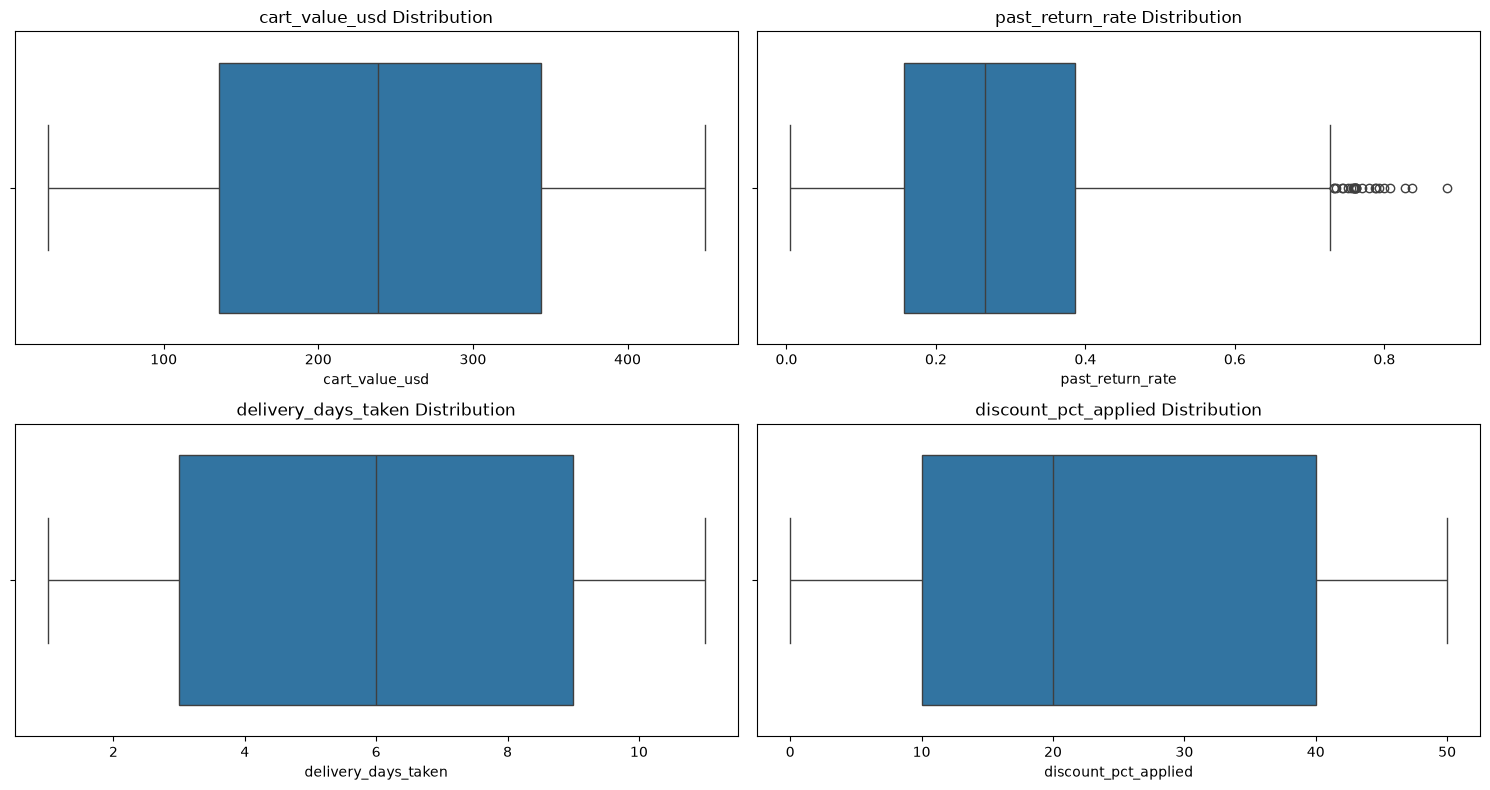

,count
product_category,
Accessories,589
Casual-Tops,1015
Footwear,752
Formal-Eveningwear,637


,count
fit_review_sentiment,
Inconsistent-Sizing,573
Runs-Slightly-Small,922
True-to-Size,1498


,count
browser_used,
Chrome,750
Edge,745
Firefox,752
Safari,746


,count
checkout_device,
Android-App,1036
Desktop-Web,989
iOS-App,968


,count
packaging_color,
Branded-Teal,1001
Kraft-Brown,1010
Minimal-White,982


,count
loyalty_card_color,
Gold,970
Platinum,1023
Silver,1000


,count
size_bracketing_flag,
0,1933
1,1060


,count
newsletter_subscriber,
0,1486
1,1507


In [167]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
axes = axes.flatten()

for i, feature in enumerate(numerical_features):
  sns.boxplot(data=ecom_data, x=feature, ax=axes[i])
  axes[i].set_title(f'{feature} Distribution')

plt.tight_layout()
plt.show()

for feature in categorical_features:
    display(ecom_data.groupby(feature)['return_risk_label'].agg(['count']).round(0))

In [168]:
ecom_data['return_risk_label'].value_counts()

return_risk_label
1    1932
0    1061
Name: count, dtype: int64

In [169]:
ecom_data[numerical_features].skew()

cart_value_usd         -0.015701
past_return_rate        0.625869
delivery_days_taken     0.027763
discount_pct_applied    0.068640
dtype: float64

# Insights

*   From the describe table, `cart_value_usd`, `discount_pct_applied` and `delivery_days_taken` are mostly symmetric while the `past_return_rate` has a right skew due to outliers.
*   `cart_value_usd`, `delivery_days_taken` and `discount_pct_applied` have no outliers while `past_return_rate` has 84% outliers which needs to be handled via preprocessing.
*   There are no duplicated and missing values in the data.


In [170]:
ecom_data.drop_duplicates(inplace=True)
ecom_data.dropna(inplace=True)
ecom_data.reset_index()

,index,cart_value_usd,past_return_rate,size_bracketing_flag,delivery_days_taken,discount_pct_applied,product_category,fit_review_sentiment,newsletter_subscriber,browser_used,checkout_device,packaging_color,loyalty_card_color,return_risk_label
0,0,172.17,0.233,1,11,10,Footwear,True-to-Size,1,Safari,Android-App,Kraft-Brown,Platinum,1
1,1,213.55,0.235,1,6,40,Accessories,True-to-Size,0,Firefox,Android-App,Branded-Teal,Silver,0
2,2,371.70,0.461,1,11,40,Formal-Eveningwear,True-to-Size,0,Firefox,iOS-App,Kraft-Brown,Gold,1
3,3,317.18,0.080,0,1,20,Footwear,Inconsistent-Sizing,0,Firefox,iOS-App,Kraft-Brown,Gold,1
4,4,152.68,0.133,0,3,40,Accessories,True-to-Size,0,Edge,iOS-App,Branded-Teal,Silver,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2988,2988,417.41,0.338,0,1,40,Casual-Tops,True-to-Size,1,Edge,iOS-App,Kraft-Brown,Silver,0
2989,2989,81.61,0.153,1,7,0,Casual-Tops,True-to-Size,0,Chrome,iOS-App,Kraft-Brown,Silver,1
2990,2990,281.06,0.234,0,4,20,Casual-Tops,True-to-Size,1,Chrome,Desktop-Web,Branded-Teal,Gold,0
2991,2991,365.23,0.288,1,1,30,Formal-Eveningwear,True-to-Size,1,Firefox,Desktop-Web,Branded-Teal,Silver,1


In [171]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

In [172]:
print(len(numerical_features)+len(categorical_features))

12


In [173]:
X = ecom_data.drop(columns=['return_risk_label'])
y = ecom_data['return_risk_label']



In [174]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [175]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (2095, 12)
Validation: (449, 12)
Test: (449, 12)


In [176]:
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

In [177]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_processed,
    y_train
)

print(y_train_smote.value_counts())

return_risk_label
1    1352
0    1352
Name: count, dtype: int64


In [178]:
pipeline_lr = Pipeline(steps=[('preprocessor', preprocessor),
                               ('feature_selection', SelectFpr(f_classif, alpha=0.05)),
                               ('classifier', LogisticRegression(random_state=42))])

param_grid_lr = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__penalty": ["l1", "l2"],
    "classifier__solver": ["liblinear"],
    "classifier__class_weight": [None, "balanced"],
}

grid_search_lr = GridSearchCV(pipeline_lr, param_grid_lr, cv=5, scoring={"f1": "f1", "roc_auc": "roc_auc"}, refit='f1', n_jobs=-1, verbose=1)
grid_search_lr.fit(X_train, y_train)

print(f"Best parameters: {grid_search_lr.best_params_}")
print(f"Best CV F1: {grid_search_lr.best_score_:.3f}")
print(f"CV ROC-AUC of that model: {grid_search_lr.cv_results_['mean_test_roc_auc'][grid_search_lr.best_index_]:.3f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits


c:\Users\buzz\Desktop\ml-portfolio-project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\buzz\Desktop\ml-portfolio-project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Best parameters: {'classifier__C': 1, 'classifier__class_weight': None, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}
Best CV F1: 0.951
CV ROC-AUC of that model: 0.985


In [179]:
pipeline_rf = Pipeline(steps=[('preprocessor', preprocessor),
                               ('feature_selection', SelectFpr(f_classif, alpha=0.05)),
                               ('classifier', RandomForestClassifier(random_state=42, n_jobs=1))])

param_grid_rf = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [None, 5, 10, 20],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__class_weight": [None, "balanced"],
}

grid_search_rf = RandomizedSearchCV(pipeline_rf, param_grid_rf, cv=5, scoring={"f1": "f1", "roc_auc": "roc_auc"}, refit='f1', n_jobs=-1, verbose=1)
grid_search_rf.fit(X_train, y_train)

print(f"Best parameters: {grid_search_rf.best_params_}")
print(f"Best CV F1: {grid_search_rf.best_score_:.3f}")
print(f"CV ROC-AUC of that model: {grid_search_rf.cv_results_['mean_test_roc_auc'][grid_search_rf.best_index_]:.3f}")

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters: {'classifier__n_estimators': 100, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 2, 'classifier__max_depth': None, 'classifier__class_weight': None}
Best CV F1: 0.924
CV ROC-AUC of that model: 0.966


In [180]:
pipeline_svm = Pipeline(steps=[('preprocessor', preprocessor),
                               ('feature_selection', SelectFpr(f_classif, alpha=0.05)),
                               ('classifier', SVC(random_state=42))])

param_grid_svm = {
    "classifier__C": [0.1, 1, 10, 100],
    "classifier__kernel": ["rbf", "linear"],
    "classifier__gamma": ["scale", 0.01, 0.1],   
    "classifier__class_weight": [None, "balanced"],
}

grid_search_svm = GridSearchCV(pipeline_svm, param_grid_svm, cv=5, scoring={"f1": "f1", "roc_auc": "roc_auc"}, refit='f1', n_jobs=-1, verbose=1)
grid_search_svm.fit(X_train, y_train)

print(f"Best parameters: {grid_search_svm.best_params_}")
print(f"Best CV F1: {grid_search_svm.best_score_:.3f}")
print(f"CV ROC-AUC of that model: {grid_search_svm.cv_results_['mean_test_roc_auc'][grid_search_svm.best_index_]:.3f}")

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best parameters: {'classifier__C': 100, 'classifier__class_weight': None, 'classifier__gamma': 0.01, 'classifier__kernel': 'rbf'}
Best CV F1: 0.956
CV ROC-AUC of that model: 0.984


In [181]:
best_models = {
    'LogisticRegression': {'model': grid_search_lr.best_estimator_, 'cv_f1': grid_search_lr.best_score_},
    'RandomForest':       {'model': grid_search_rf.best_estimator_, 'cv_f1': grid_search_rf.best_score_},
    'SVM':                {'model': grid_search_svm.best_estimator_, 'cv_f1': grid_search_svm.best_score_},
}

best_model_name = max(best_models, key=lambda k: best_models[k]['cv_f1'])
best_model_info = best_models[best_model_name]

print(f"The best model is {best_model_name} with a CV F1 of {best_model_info['cv_f1']:.3f}")

The best model is SVM with a CV F1 of 0.956


,cv_f1,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
model,,,,,,
LogisticRegression,0.951,0.931,0.951,0.941,0.946,0.986
RandomForest,0.924,0.900,0.915,0.931,0.923,0.970
SVM,0.956,0.940,0.955,0.952,0.953,0.988


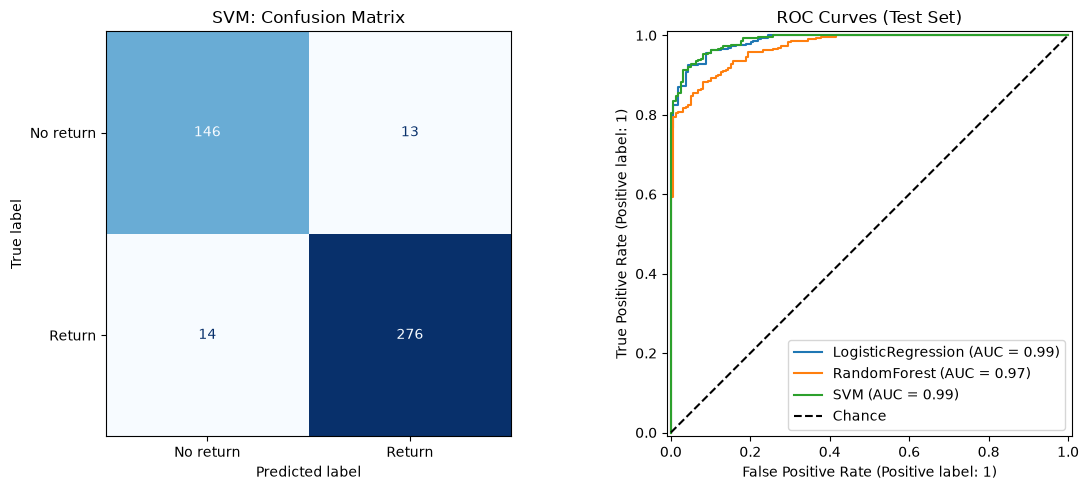

In [182]:
def get_scores(model, X):
    """Continuous scores for ROC-AUC (SVC has no predict_proba by default)."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

results = []
for name, info in best_models.items():
    y_pred = info['model'].predict(X_test)
    y_score = get_scores(info['model'], X_test)
    results.append({
        'model': name,
        'cv_f1': info['cv_f1'],
        'test_accuracy': accuracy_score(y_test, y_pred),
        'test_precision': precision_score(y_test, y_pred),
        'test_recall': recall_score(y_test, y_pred),
        'test_f1': f1_score(y_test, y_pred),
        'test_roc_auc': roc_auc_score(y_test, y_score),
    })

results_df = pd.DataFrame(results).set_index('model').round(3)
display(results_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

best_pred = best_model_info['model'].predict(X_test)
ConfusionMatrixDisplay(confusion_matrix(y_test, best_pred),
                       display_labels=['No return', 'Return']).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'{best_model_name}: Confusion Matrix')

for name, info in best_models.items():
    RocCurveDisplay.from_predictions(y_test, get_scores(info['model'], X_test), name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--', label='Chance')
axes[1].set_title('ROC Curves (Test Set)')
axes[1].legend()

plt.tight_layout()
plt.show()

In [183]:
joblib.dump(best_model_info['model'], 'ecommerce_returns_model.pkl')

['ecommerce_returns_model.pkl']